![Image in a markdown cell](https://cursos.utnba.centrodeelearning.com/pluginfile.php/1/theme_space/customlogo/1738330016/Logo%20UTN%20Horizontal.png)



# **Diplomado de Ciencia de Datos y Análisis Avanzado**
# **Trabajo Práctico Integrador**


---

# **Proyecto: Predicción de tipo de obesidad según hábitos de vida**

## **Curso:** Diplomatura en Ciencia de Datos y Analisis Avanzado

# **Nombres de los Miembros del Equipo:**
### *   ANA LAURA CAO
### *   FEDERICO TRANI
### *   MARIA PIA PEDROSO
### *   HERNAN RODRIGUES NEVES
### *   ESTEFANIA SANGUINETTI

# **Objetivo:**
## El conjunto de datos contiene información sobre hábítos de vida y diferentes tipos de obesidad. El objetivo de este trabajo es poder entrenar diferentes modelos con ese dataset para que luego al informar hábitos de vida de nuevas personas se pueda predecir qué tipo de obesidad podrías tener si se continúa con esa rutina.

# **Contexto:**
## El sobrepeso está aumentando en la sociedad actual, afectando también a niños y adolescentes: desde 1990, se ha duplicado entre los adultos de todo el mundo y se ha cuadruplicado entre los adolescentes. A nivel mundial la prevalencia de bajo peso, relacionada con la desnutrición, ha logrado disminuir, pero el sobrepeso, que también suele estar asociado a la desnutrición, está en aumento. Con este dataset que contiene datos reales de hábitos de vida de personas de Perú, Colombia y México y sus correspondientes niveles de obesidad, se intenta entender mejor cuáles son los hábitos que más contribuyen a esta problemática.


# 0. **Configuración Inicial e Importación de Librerías**

## En esta sección, importaremos todas las librerías necesarias para el proyecto. Es una buena práctica tener todas las importaciones en la primera celda.


In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np
import time

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluación
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, f1_score, recall_score, precision_score)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

import warnings
warnings.filterwarnings('ignore')

In [2]:
# --- Carga del dataset ---
import os, glob
archivo = 'ObesityDataSet_raw_and_data_sinthetic.csv'

if os.path.exists(archivo):            # OPCIÓN A: CSV subido a Colab
    ruta = archivo
elif os.path.exists('ObesityDataSet.csv'):
    ruta = 'ObesityDataSet.csv'
else:                                   # OPCIÓN B: buscarlo en Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    candidatos = (glob.glob('/content/drive/.shortcut-targets-by-id/*/UTN_Grupo 30/**/' + archivo, recursive=True)
                  or glob.glob('/content/drive/.shortcut-targets-by-id/**/' + archivo, recursive=True)
                  or glob.glob('/content/drive/MyDrive/**/' + archivo, recursive=True))
    if not candidatos:
        raise FileNotFoundError("No se encontró el CSV en Drive. Agregá un acceso directo a la carpeta 'UTN_Grupo 30' en tu Mi unidad o subí el CSV a Colab.")
    ruta = candidatos[0]

print("Leyendo:", ruta)
df = pd.read_csv(ruta)
print("Shape:", df.shape)
print("\nColumnas:", list(df.columns))
display(df.head())

Leyendo: ObesityDataSet.csv
Shape: (2111, 17)

Columnas: ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


#  **1. Carga de Datos**




In [3]:
print(f"Dataset cargado correctamente: {df.shape[0]} filas x {df.shape[1]} columnas.")
display(df.head())

Dataset cargado correctamente: 2111 filas x 17 columnas.


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Se puede encontrar el dataset en el siguiente DOI:[10.24432/C5H31Z](https://https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition), del UCI Machine Learning Repository



# 2. **Análisis Exploratorio de Datos (EDA)**

## En esta fase, exploraremos el conjunto de datos para entender mejor nuestros datos, encontrar patrones, identificar valores faltantes y visualizar relaciones entre las características y la variable objetivo (`NObeyesdad`).


### 2.1 Información general del dataset

In [4]:
# Tipos de datos y valores no nulos
print("Información del dataset:")
df.info()

print("\nEstadísticas descriptivas de variables numéricas:")
display(df.describe())

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF      

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [5]:
# Verificación de valores nulos
nulos = df.isnull().sum()
print("Valores nulos por columna:")
print(nulos[nulos > 0] if nulos.sum() > 0 else "No hay valores nulos en el dataset.")

# Verificación de duplicados
duplicados = df.duplicated().sum()
print(f"\nFilas duplicadas: {duplicados}")

# Hay 24 filas duplicadas: se eliminan en la sección 3 (Preprocesamiento).

Valores nulos por columna:
No hay valores nulos en el dataset.

Filas duplicadas: 24


### 2.2 Distribución de la variable objetivo

Analizamos el balance de las clases, clave para elegir la métrica de evaluación.

                     Cantidad  Porcentaje (%)
NObeyesdad                                   
Insufficient_Weight       272           12.88
Normal_Weight             287           13.60
Obesity_Type_I            351           16.63
Obesity_Type_II           297           14.07
Obesity_Type_III          324           15.35
Overweight_Level_I        290           13.74
Overweight_Level_II       290           13.74


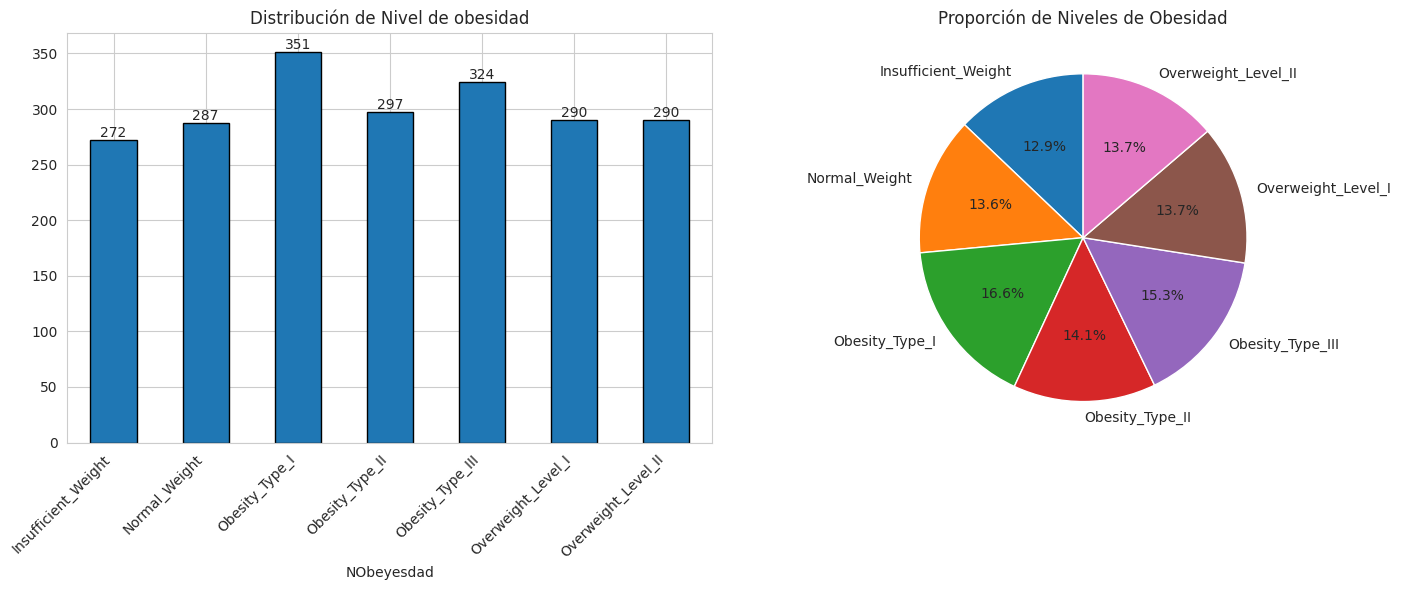


El dataset está relativamente balanceado entre las 7 clases de obesidad/peso.


In [6]:
counts = df['NObeyesdad'].value_counts().sort_index()
pct    = df['NObeyesdad'].value_counts(normalize=True).sort_index().mul(100).round(2)

print(pd.DataFrame({'Cantidad': counts, 'Porcentaje (%)': pct}))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico de barras
counts.plot(kind='bar', ax=ax[0], edgecolor='black')
ax[0].set_title('Distribución de Nivel de obesidad')
ax[0].set_xticklabels(counts.index, rotation=45, ha='right')
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}',
                   (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')

# Gráfico de torta
ax[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
ax[1].set_title('Proporción de Niveles de Obesidad')

plt.tight_layout()
plt.show()

print("\nEl dataset está relativamente balanceado entre las 7 clases de obesidad/peso.")

### 2.3 Análisis de variables numéricas por clase

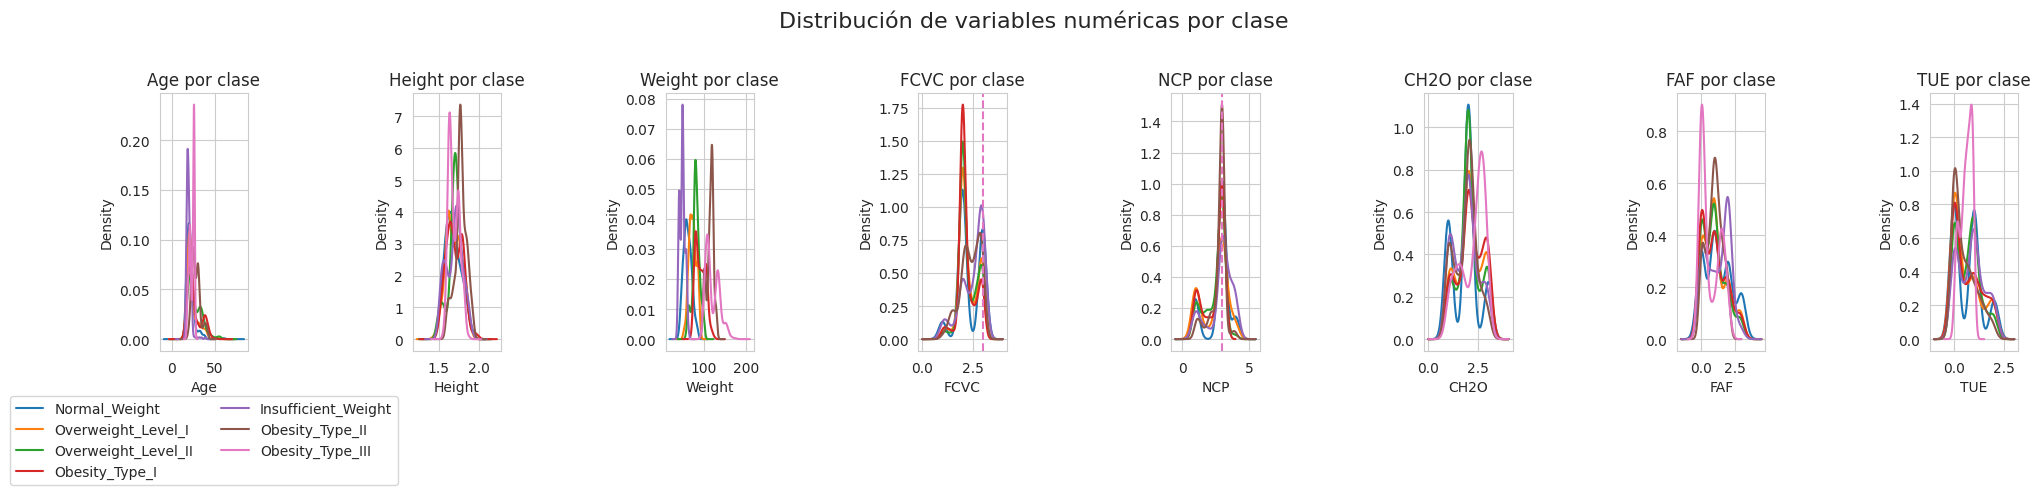

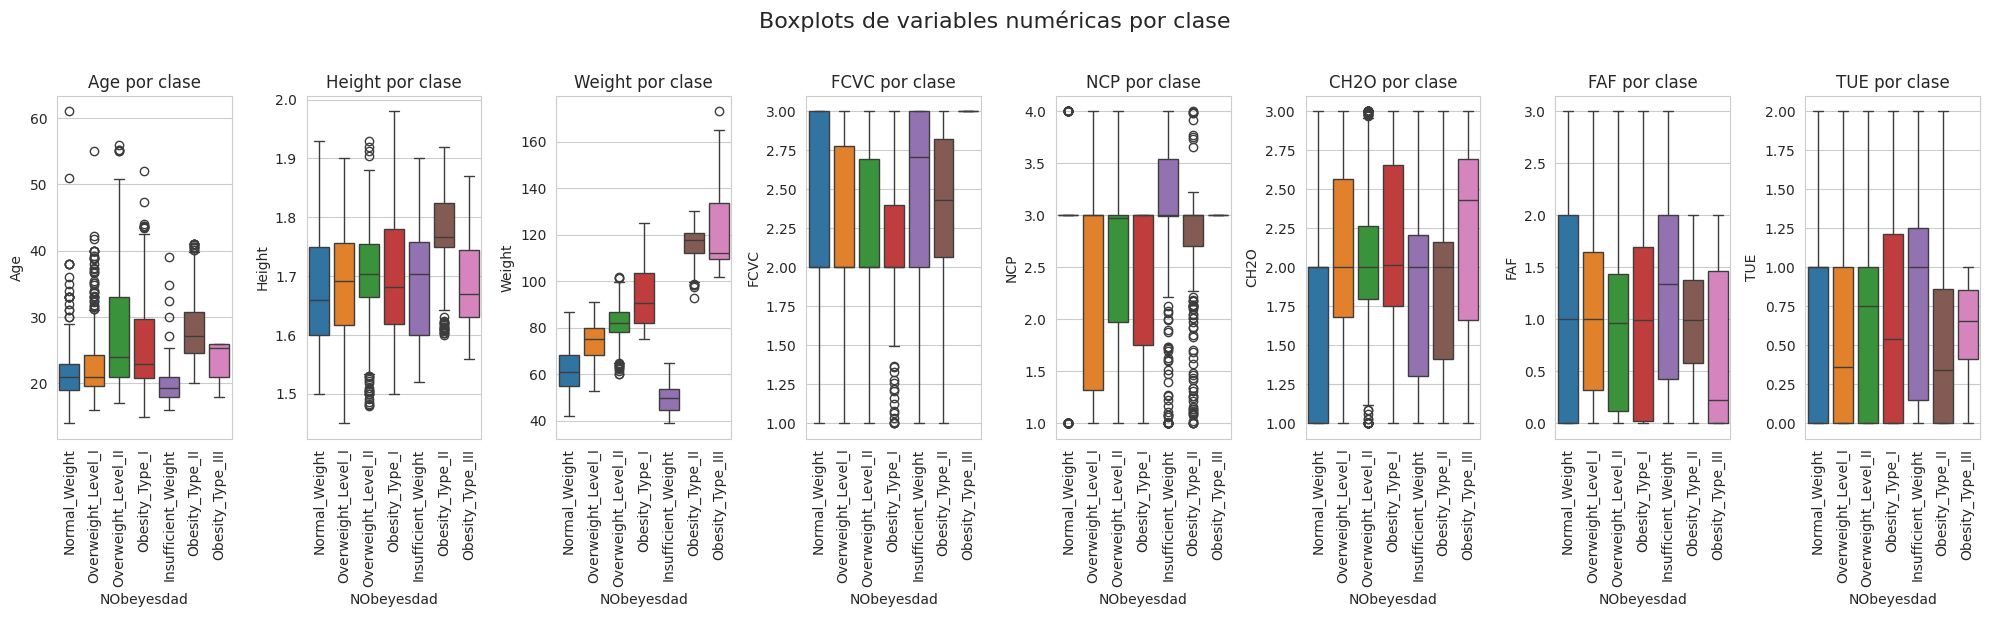

In [7]:
num_cols = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
clases = df['NObeyesdad'].unique()

# 1. Gráficos de densidad (KDE)
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 5))
colors = sns.color_palette("tab10", len(clases))

for i, col in enumerate(num_cols):
    for clase, color in zip(clases, colors):
        subset = df[df['NObeyesdad'] == clase]
        # Evitamos graficar si el subconjunto está vacío
        if len(subset) > 0:
            try:
                subset[col].plot(kind='kde', ax=axes[i], label=clase, color=color)
            except np.linalg.LinAlgError:
                # Si los datos tienen varianza cero (ej. todos los valores son idénticos),
                # dibujamos una línea vertical en su valor único en lugar de fallar.
                val_unico = subset[col].iloc[0]
                axes[i].axvline(x=val_unico, color=color, linestyle='--', label=f'{clase} (cons.)')

    axes[i].set_title(f'{col} por clase')
    axes[i].set_xlabel(col)
    if i == 0:
        axes[i].legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=2)
    else:
        axes[i].get_legend().remove() if axes[i].get_legend() else None

plt.suptitle('Distribución de variables numéricas por clase', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# 2. Boxplots por clase
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 6))
for i, col in enumerate(num_cols):
    sns.boxplot(x='NObeyesdad', y=col, data=df, ax=axes[i], hue='NObeyesdad',
                palette="tab10", legend=False)
    axes[i].set_title(f'{col} por clase')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90)

plt.suptitle('Boxplots de variables numéricas por clase', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

Vemos que obesidad de tipo 2 y 3 tienen mayor edad en promedio. Obesidad de tipo 2 tiene también mayor altura promedio. Contrario a lo que pensábamos, el consumo de verdura es mayor en obesidad de tipo 2 y 3, además de peso insuficiente. Obesidad de tipo 3 también bebe más agua en promedio que el resto. Para la frecuencia de actividad fisica, los de peso insuficiente hacen más en promedio que el resto, y los de obesidad de tipo 3 menos en promedio que el resto. Por último, el uso de de dispositivos electrónicos es diferente entre grupos, con el de peso insuficiente como más uso y el de obesidad de tipo 2 menos uso en promedio. En general entonces estas variables no parecen diferenciar mucho entre clases, a lo sumo principalmente para peso insuficiente y obesidad de tipo 3, especialmente la variable de actividad fisica.  

### 2.4 Análisis de variables categóricas por clase


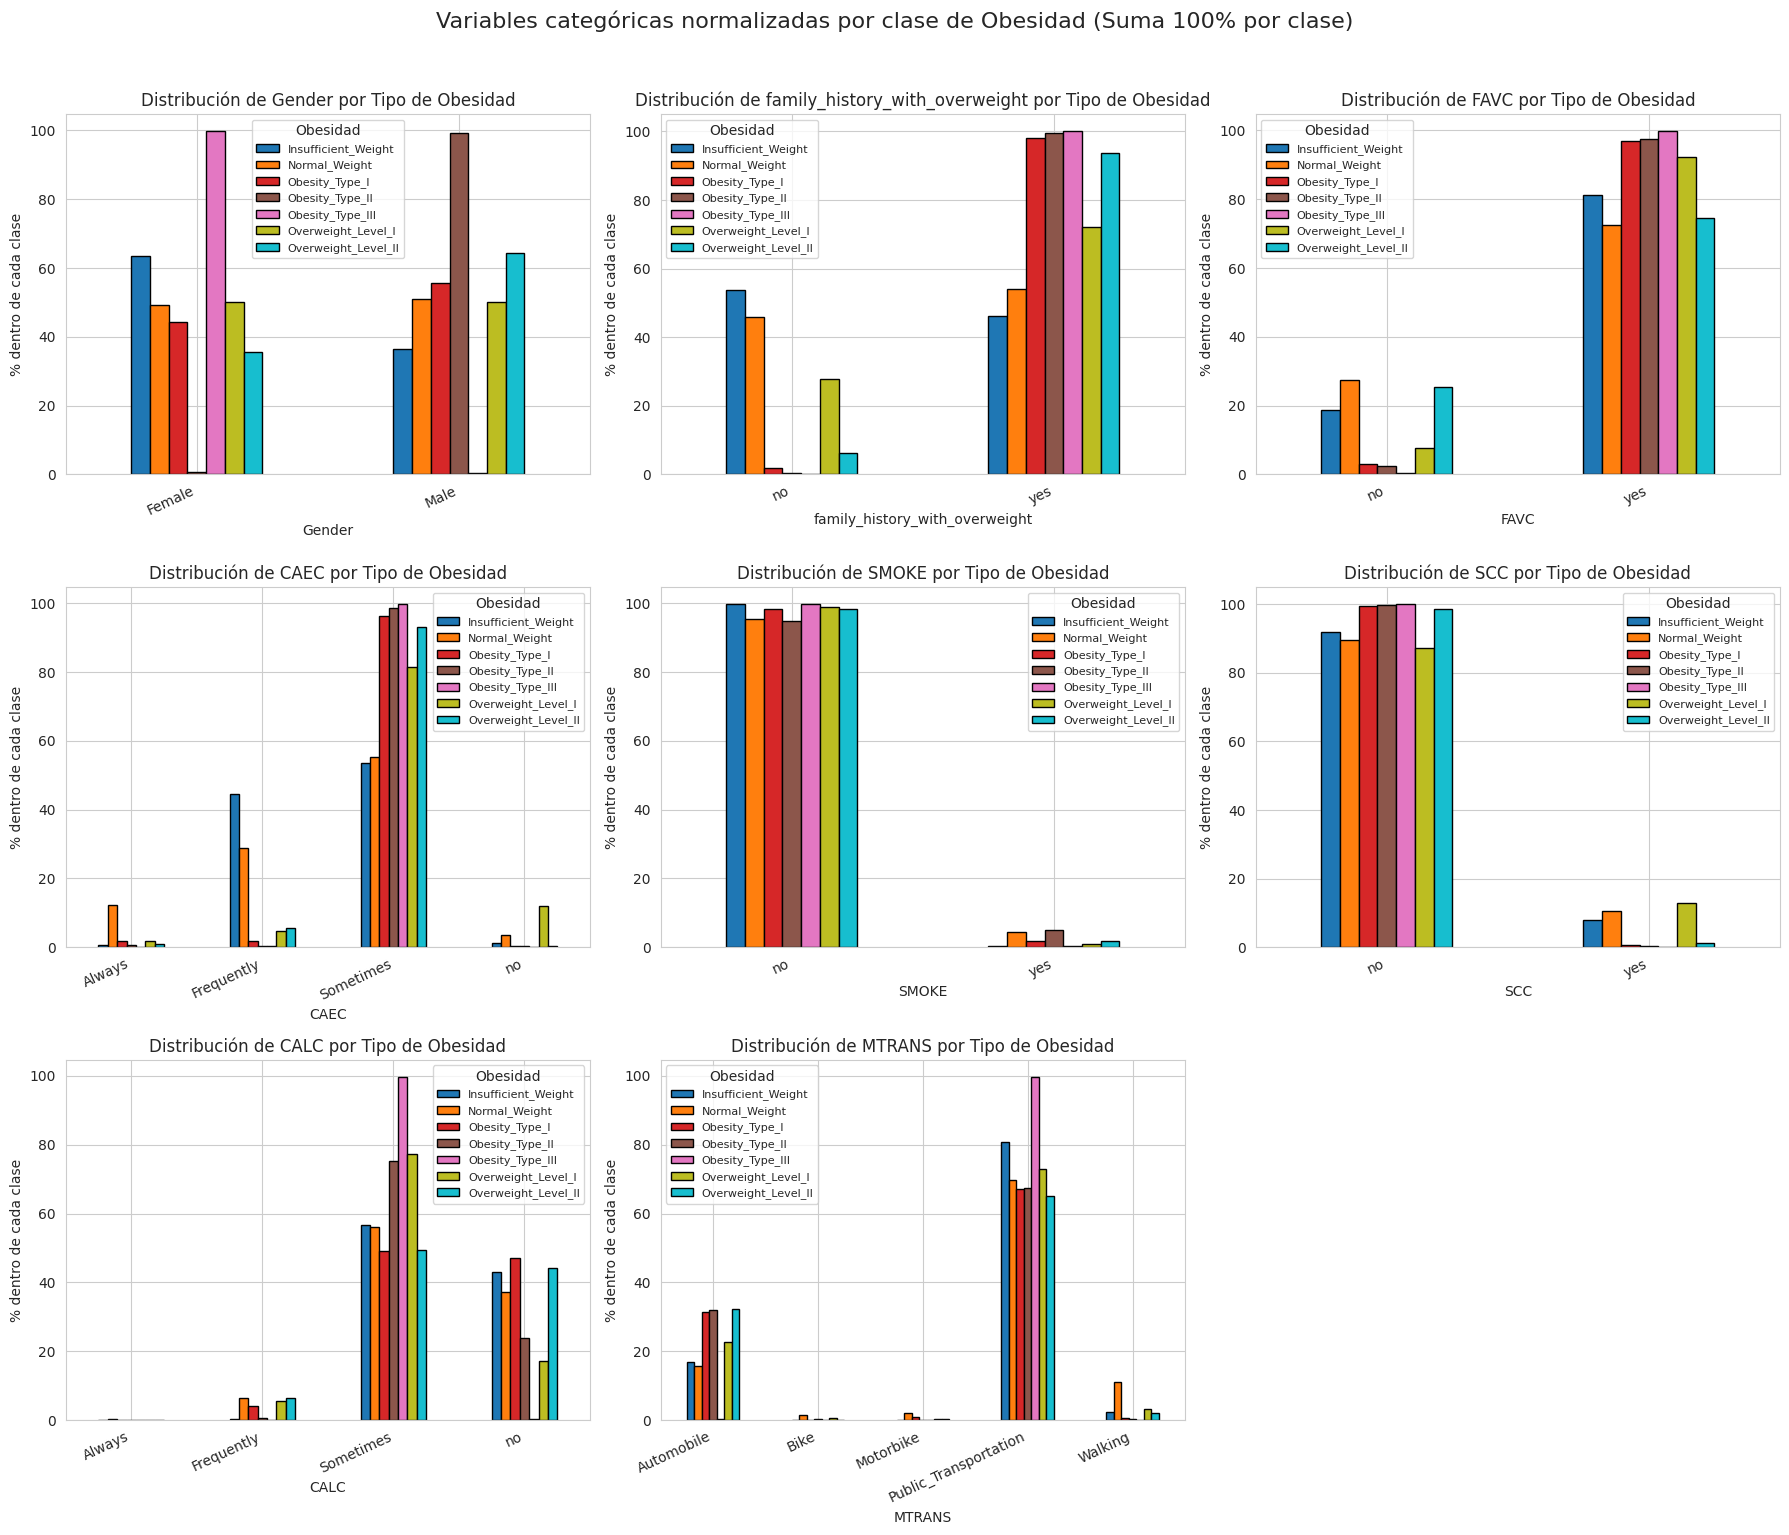

In [8]:
plot_cols = ["Gender","family_history_with_overweight","FAVC","CAEC","SMOKE","SCC","CALC","MTRANS"]

n = len(plot_cols)
rows = (n + 2) // 3
fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    # Creamos la tabla de contingencia
    ct = df.groupby([col, 'NObeyesdad']).size().unstack(fill_value=0)

    # Normalizamos por columnas (NObeyesdad) para que cada clase de obesidad sume 100%
    # Así vemos cómo se distribuyen los hábitos DENTRO de cada tipo de peso.
    ct_pct = ct.div(ct.sum(axis=0), axis=1) * 100

    # Graficar y conservar la referencia para configurar la leyenda
    ct_pct.plot(kind='bar', ax=axes[i], colormap='tab10', edgecolor='black')

    axes[i].set_title(f'Distribución de {col} por Tipo de Obesidad')
    axes[i].set_ylabel('% dentro de cada clase')
    axes[i].set_xlabel(col)

    # Añadir leyenda con los nombres de las clases de obesidad
    axes[i].legend(ct_pct.columns, title='Obesidad', fontsize=8, loc='best')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=25, ha='right')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Variables categóricas normalizadas por clase de Obesidad', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### **Análisis de los Gráficos de Variables Categóricas:**

* **Género (Gender):** Se observa una marcada diferencia en los tipos de obesidad extrema según el género. La **Obesidad Tipo III** se presenta casi exclusivamente en mujeres, mientras que la **Obesidad Tipo II** predomina fuertemente en hombres.
* **Historial Familiar de Sobrepeso (family_history_with_overweight):** Las personas sin historial familiar de sobrepeso tienen en su mayoría peso normal o peso insuficiente. Mientras que las personas con historial de sobrepeso en la familia suelen tener algún tipo o nivel de obesidad.
* **Consumo de Alimentos entre Comidas (CAEC):** La mayoría de las categorías de tipo o nivel de peso consumen a veces alimento entre comidas, están dentro de (`sometimes`).
* **Monitoreo diario de calorías (SCC):** La gran mayoria de individuos no monitorea el consumo diario de calorías sin importar el tipo o nivel de obesidad.
* **Consumo de Alcohol (CALC) y Tabaco (SMOKE):** El hábito de fumar no parece mostrar una correlación directa o diferenciadora clara con los niveles de obesidad. Respecto al consumo de alcohol, pareciera que hay algunos tipos o niveles de obesidad que están más representados con un consumo de alcohol de vez en cuando,(`sometimes`)
* **Medio de Transporte (MTRANS):** El uso de transporte público o automóvil está ampliamente extendido en todos los niveles, sin mostrar ninguna tendencia en particular.

### 2.5 Correlación entre variables numéricas

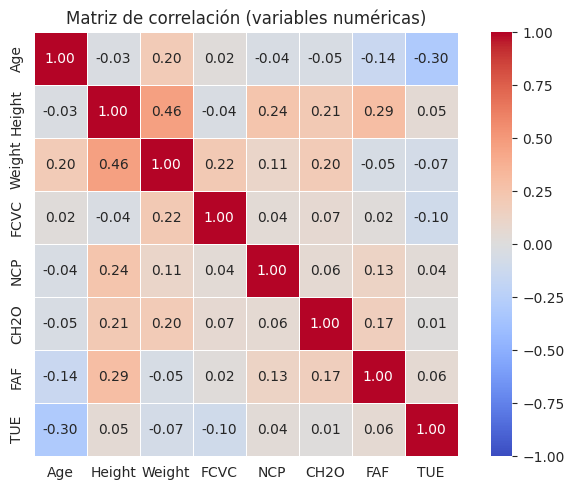

In [9]:
temp = df[num_cols].copy()
temp['NObeyesdad'] = df['NObeyesdad']

plt.figure(figsize=(7, 5))
# Agregamos numeric_only=True para omitir la columna categórica 'NObeyesdad' en la correlación
sns.heatmap(temp.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', square=True,
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de correlación (variables numéricas)')
plt.tight_layout()
plt.show()

Las variables numéricas de hábitos tienen correlaciones bajas entre sí, por lo que no hay redundancia que obligue a eliminar alguna. La única correlación relevante es entre **Height** y **Weight**, que de todos modos se excluyen del modelo. Como la variable objetivo es categórica, su relación con los hábitos se analiza con los gráficos por clase de las secciones 2.3 y 2.4.

# **3. Preprocesamiento de Datos**

## Prepararemos los datos para que puedan ser utilizados

Usamos un ColumnTransformer dentro de un Pipeline para evitar data leakage (todo se ajusta solo sobre train). Decisiones:

- Se elimina `Height` y `Weight` ya que son las variables con las cuales se construye la variable objetivo.
- Se eliminan las 24 filas duplicadas. Al ser un dataset con parte de los datos hechos artificialmente, esas filas pueden ser redundantes.
- **Categóricas**: OneHotEncoder para no introducir un orden artificial cuando no lo tienen y OrdinalEncoder para las variables que sí tienen un orden natural
- El target se codifica con un **LabelEncoder** (en la sección 4), porque XGBoost y LightGBM necesitan la clase en formato numérico.

In [10]:
# 1. Identificar y mostrar las filas duplicadas
duplicados_df = df[df.duplicated(keep=False)]
print(f"Se encontraron {df.duplicated().sum()} filas duplicadas (mostrando {len(duplicados_df)} registros que son copias entre sí):")
display(duplicados_df.head(10))  # Mostramos las primeras 10 filas duplicadas para inspección

# 2. Eliminar las filas duplicadas del dataset conservando la primera aparición
df = df.drop_duplicates(keep='first')
print(f"\nFilas duplicadas eliminadas. Nuevo shape del dataset: {df.shape}")

# 3. Eliminar las columnas Weight y Height tal como se indicó en las decisiones de diseño
# (se remueven con sensibilidad a mayúsculas/minúsculas)
columnas_a_eliminar = [col for col in ['Weight', 'Height', 'weight', 'height'] if col in df.columns]
df_prepro = df.drop(columns=columnas_a_eliminar)

X = df_prepro.drop(columns=['NObeyesdad'])
y = df_prepro['NObeyesdad'].astype(object)




Se encontraron 24 filas duplicadas (mostrando 33 registros que son copias entre sí):


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
97,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
98,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
105,Female,25.0,1.57,55.0,no,yes,2.0,1.0,Sometimes,no,2.0,no,2.0,0.0,Sometimes,Public_Transportation,Normal_Weight
106,Female,25.0,1.57,55.0,no,yes,2.0,1.0,Sometimes,no,2.0,no,2.0,0.0,Sometimes,Public_Transportation,Normal_Weight
145,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
174,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
179,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
184,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
208,Female,22.0,1.69,65.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight
209,Female,22.0,1.69,65.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight



Filas duplicadas eliminadas. Nuevo shape del dataset: (2087, 17)


In [11]:
from sklearn.preprocessing import OrdinalEncoder

# 1. Definimos las columnas numéricas
num_cols = ['Age', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# 2. Definimos las variables categóricas con orden (Ordinales) y sus categorías en el orden correcto
ordinal_cols = ['CAEC', 'CALC']

# Especificamos el orden explícito de peor a mejor o menor a mayor
categorias_ordenadas = [
    ['no', 'Sometimes', 'Frequently', 'Always'],  # Orden para CAEC
    ['no', 'Sometimes', 'Frequently', 'Always']   # Orden para CALC
]

# 3. Definimos las variables categóricas sin orden (Nominales) para transformarlas en Dummies
nominal_cols = ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS']

# 4. Construimos el ColumnTransformer
preprocesador = ColumnTransformer(transformers=[
    # Numéricas: Imputamos nulos (si los hubiera) y estandarizamos
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),

    # Ordinales: Mapeo ordenado de categorías
    ('ord', OrdinalEncoder(categories=categorias_ordenadas, handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),

    # Nominales: Creación de variables Dummy (One-Hot Encoding)
    ('nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), nominal_cols)
])

print("Preprocesador configurado correctamente.")

Preprocesador configurado correctamente.


In [12]:
# Separación de datos en entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} filas | Validación: {X_val.shape[0]} filas")
print("Distribución de la variable objetivo en Train:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Train: 1669 filas | Validación: 418 filas
Distribución de la variable objetivo en Train:
NObeyesdad
Obesity_Type_I         16.84
Obesity_Type_III       15.52
Obesity_Type_II        14.20
Overweight_Level_II    13.90
Normal_Weight          13.48
Overweight_Level_I     13.24
Insufficient_Weight    12.82
Name: proportion, dtype: float64


In [ ]:
# Los datos ya están separados en X_train, X_val, y_train, y_val correctamente.
# El preprocesador guardado en la variable 'preprocesador' está listo para transformar las variables.

X_train_preprocesado = preprocesador.fit_transform(X_train)
print(f"Shape final tras aplicar el preprocesador: {X_train_preprocesado.shape}")

# 4. Modelado y Evaluación
Siguiendo la devolución de la pre-entrega, comparamos los modelos de
referencia (Regresión Logística y Random Forest) contra UN modelo de boosting.
Primero probamos XGBoost y LightGBM sin ajustar y nos quedamos con el mejor
de los dos, sin sumar modelos por sumar. Validación cruzada estratificada de
5 pliegues **solo sobre train**; el 20% de validación queda como holdout.
Métrica principal: F1 macro.

Cada modelo va dentro de un pipeline con el preprocesador. Métrica principal: **Macro F1-Score**. Además reportamos **Accuracy** y **Matriz de Confusión** para ver entre qué niveles de obesidad se equivoca más el modelo. También medimos el tiempo de entrenamiento.

In [13]:
# Instalar e importar lo que falta (en Colab xgboost ya viene; lightgbm también)
# !pip install -q xgboost lightgbm
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# XGBoost/LightGBM necesitan el target numérico: lo codificamos con LabelEncoder
# (ajustado solo en train). Guardamos le.classes_ para volver a los nombres.
le = LabelEncoder().fit(y_train)
y_train_enc = le.transform(y_train)
y_val_enc = le.transform(y_val)
print(dict(enumerate(le.classes_)))

{0: 'Insufficient_Weight', 1: 'Normal_Weight', 2: 'Obesity_Type_I', 3: 'Obesity_Type_II', 4: 'Obesity_Type_III', 5: 'Overweight_Level_I', 6: 'Overweight_Level_II'}


,Modelo,F1 macro (CV),Desvío F1,Accuracy (CV),Tiempo (s)
3,LightGBM,0.846,0.028,0.848,8.026
1,Random Forest,0.841,0.016,0.845,5.046
2,XGBoost,0.832,0.030,0.836,5.466
0,Regresión Logística,0.550,0.043,0.576,5.983


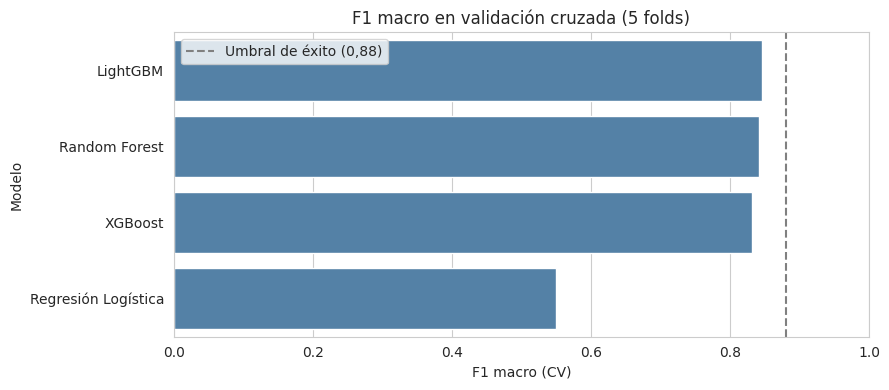

In [14]:
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=2000, random_state=42),
    'Random Forest':       RandomForestClassifier(random_state=42, n_jobs=-1),
    'XGBoost':             XGBClassifier(random_state=42, eval_metric='mlogloss', n_jobs=-1),
    'LightGBM':            LGBMClassifier(random_state=42, verbose=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []
for nombre, modelo in modelos.items():
    pipe = Pipeline([('prep', preprocesador), ('model', modelo)])
    t0 = time.time()
    scores = cross_validate(pipe, X_train, y_train_enc, cv=cv,
                            scoring=['f1_macro', 'accuracy'], n_jobs=-1)
    resultados.append({
        'Modelo': nombre,
        'F1 macro (CV)': scores['test_f1_macro'].mean(),
        'Desvío F1': scores['test_f1_macro'].std(),
        'Accuracy (CV)': scores['test_accuracy'].mean(),
        'Tiempo (s)': time.time() - t0,
    })

tabla_cv = pd.DataFrame(resultados).sort_values('F1 macro (CV)', ascending=False)
display(tabla_cv.round(3))

plt.figure(figsize=(9, 4))
sns.barplot(data=tabla_cv, y='Modelo', x='F1 macro (CV)', color='steelblue')
plt.axvline(0.88, ls='--', color='gray', label='Umbral de éxito (0,88)')
plt.xlim(0, 1); plt.legend(); plt.title('F1 macro en validación cruzada (5 folds)')
plt.tight_layout(); plt.show()

### 4.1 Optimización de hiperparámetros
Nos quedamos con el mejor boosting (en nuestra corrida fue LightGBM:
F1 0,846 vs 0,832 de XGBoost) y ajustamos los 3 modelos finales con
RandomizedSearchCV usando la misma validación cruzada.

In [15]:
mejor_boosting = 'LightGBM' if tabla_cv.set_index('Modelo').loc['LightGBM', 'F1 macro (CV)'] >= \
                 tabla_cv.set_index('Modelo').loc['XGBoost', 'F1 macro (CV)'] else 'XGBoost'
print('Boosting elegido:', mejor_boosting)

grillas = {
    'Regresión Logística': (LogisticRegression(max_iter=3000, random_state=42), {
        'model__C': [0.01, 0.1, 1, 10, 100]}),
    'Random Forest': (RandomForestClassifier(random_state=42, n_jobs=-1), {
        'model__n_estimators': [200, 400, 600],
        'model__max_depth': [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 'log2', 0.5]}),
    'XGBoost': (XGBClassifier(random_state=42, eval_metric='mlogloss', n_jobs=-1), {
        'model__n_estimators': [200, 400, 600],
        'model__max_depth': [3, 5, 7, 9],
        'model__learning_rate': [0.03, 0.05, 0.1, 0.2],
        'model__subsample': [0.7, 0.85, 1.0],
        'model__colsample_bytree': [0.6, 0.8, 1.0],
        'model__reg_lambda': [0.5, 1, 3]}),
    'LightGBM': (LGBMClassifier(random_state=42, verbose=-1), {
        'model__n_estimators': [200, 400, 600],
        'model__num_leaves': [15, 31, 63],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__subsample': [0.7, 0.85, 1.0],
        'model__subsample_freq': [1],
        'model__colsample_bytree': [0.6, 0.8, 1.0],
        'model__reg_lambda': [0, 1, 3]}),
}
# dejamos solo el boosting ganador
grillas.pop('XGBoost' if mejor_boosting == 'LightGBM' else 'LightGBM')

from sklearn.model_selection import ParameterGrid
busquedas = {}
for nombre, (modelo, grilla) in grillas.items():
    rs = RandomizedSearchCV(Pipeline([('prep', preprocesador), ('model', modelo)]),
                            grilla, n_iter=min(12, len(ParameterGrid(grilla))),
                            scoring='f1_macro', cv=cv,
                            random_state=42, n_jobs=-1)
    rs.fit(X_train, y_train_enc)
    busquedas[nombre] = rs
    print(f"{nombre}: F1 macro CV = {rs.best_score_:.3f}")
    print("   ", rs.best_params_)

Boosting elegido: LightGBM
Regresión Logística: F1 macro CV = 0.557
    {'model__C': 100}
Random Forest: F1 macro CV = 0.848
    {'model__n_estimators': 600, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 20}
LightGBM: F1 macro CV = 0.844
    {'model__subsample_freq': 1, 'model__subsample': 1.0, 'model__reg_lambda': 0, 'model__num_leaves': 63, 'model__n_estimators': 200, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


## 4.2 Ingeniería de variables

Siguiendo lo planteado en el informe, creamos índices que combinan hábitos. Se calculan dentro del pipeline (con un `FunctionTransformer`), así que no hay fuga de información y la función `recomendar()` sigue funcionando con las columnas originales:

* **sedentarismo** = TUE / (FAF + 1): más pantallas y menos actividad física dan un valor más alto.
* **habitos_saludables** = FCVC + CH2O + FAF (verduras + agua + actividad física).
* **riesgo_dieta** = FAVC (sí = 1) + CAEC + CALC (no = 0 … siempre = 3).
* **transporte_activo** = 1 si se mueve caminando o en bici.
* **familia_x_dieta** = antecedente familiar × riesgo_dieta.

Para cada modelo ya optimizado comparamos el F1 macro de validación cruzada con y sin estas variables (mismos hiperparámetros y mismos 5 folds). Las versiones "+ FE" se suman a la comparación de la sección 5, que sigue eligiendo el ganador por CV.

**Resultado:** las variables nuevas no mejoran el F1 macro; lo bajan alrededor de 0,01 en los tres modelos (Random Forest: 0,848 → 0,835). Los modelos de árboles ya capturan estas combinaciones a partir de las variables originales, y los índices suman ruido. Por eso el modelo final queda **sin** ingeniería de variables.

In [16]:
# 4.2 Ingeniería de variables (índices combinados de hábitos)
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone
from types import SimpleNamespace

mapa_frec = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}

def agregar_features(X):
    X = X.copy()
    # Índice de sedentarismo: más pantallas y menos actividad física => valor más alto
    X['sedentarismo'] = X['TUE'] / (X['FAF'] + 1)
    # Hábitos saludables: verduras (1-3) + agua (1-3) + actividad física (0-3)
    X['habitos_saludables'] = X['FCVC'] + X['CH2O'] + X['FAF']
    # Riesgo alimentario: hipercalóricos + picoteo entre comidas + alcohol
    X['riesgo_dieta'] = ((X['FAVC'] == 'yes').astype(int)
                         + X['CAEC'].map(mapa_frec).fillna(0)
                         + X['CALC'].map(mapa_frec).fillna(0))
    # Transporte activo (camina o va en bici)
    X['transporte_activo'] = X['MTRANS'].isin(['Walking', 'Bike']).astype(int)
    # Interacción: antecedente familiar x riesgo alimentario
    X['familia_x_dieta'] = (X['family_history_with_overweight'] == 'yes').astype(int) * X['riesgo_dieta']
    return X

nuevas_cols = ['sedentarismo', 'habitos_saludables', 'riesgo_dieta', 'transporte_activo', 'familia_x_dieta']

# Mismo preprocesador que en la sección 3, con un paso previo que crea las variables nuevas
preprocesador_fe = Pipeline([
    ('fe', FunctionTransformer(agregar_features)),
    ('ct', ColumnTransformer(transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), num_cols + nuevas_cols),
        ('ord', OrdinalEncoder(categories=categorias_ordenadas, handle_unknown='use_encoded_value',
                               unknown_value=-1), ordinal_cols),
        ('nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), nominal_cols),
    ])),
])

print("Variables nuevas (train):")
display(agregar_features(X_train)[nuevas_cols].describe().round(2))

# Comparamos cada modelo ya optimizado, con y sin las variables nuevas (misma CV de 5 folds)
filas_fe = []
for nombre in [k for k in busquedas if not k.endswith('+ FE')]:
    rs = busquedas[nombre]
    modelo = rs.best_estimator_.named_steps['model']
    pipe_fe = Pipeline([('prep', preprocesador_fe), ('model', clone(modelo))])
    sc = cross_val_score(pipe_fe, X_train, y_train_enc, cv=cv, scoring='f1_macro', n_jobs=-1)
    filas_fe.append({'Modelo': nombre, 'F1 CV sin FE': rs.best_score_,
                     'F1 CV con FE': sc.mean(), 'Diferencia': sc.mean() - rs.best_score_})
    pipe_fe.fit(X_train, y_train_enc)
    # Lo sumamos a 'busquedas' para que la sección 5 lo compare junto al resto
    busquedas[f'{nombre} + FE'] = SimpleNamespace(best_score_=sc.mean(), best_estimator_=pipe_fe)

tabla_fe = pd.DataFrame(filas_fe)
display(tabla_fe.round(3))

Variables nuevas (train):


,sedentarismo,habitos_saludables,riesgo_dieta,transporte_activo,familia_x_dieta
count,1669.00,1669.00,1669.00,1669.00,1669.00
mean,0.39,5.43,2.76,0.03,2.26
std,0.43,1.25,0.75,0.16,1.23
min,0.00,2.00,0.00,0.00,0.00
25%,0.00,4.48,2.00,0.00,2.00
50%,0.32,5.49,3.00,0.00,3.00
75%,0.54,6.23,3.00,0.00,3.00
max,2.00,9.00,6.00,1.00,6.00


,Modelo,F1 CV sin FE,F1 CV con FE,Diferencia
0,Regresión Logística,0.557,0.549,-0.008
1,Random Forest,0.848,0.835,-0.013
2,LightGBM,0.844,0.831,-0.012


# 5. Evaluación final en el holdout (20%)

In [17]:
filas = []
for nombre, rs in busquedas.items():
    pred = rs.best_estimator_.predict(X_val)
    filas.append({'Modelo': nombre,
                  'F1 macro CV': rs.best_score_,
                  'F1 macro holdout': f1_score(y_val_enc, pred, average='macro'),
                  'Accuracy holdout': accuracy_score(y_val_enc, pred)})
tabla_final = pd.DataFrame(filas).sort_values('F1 macro CV', ascending=False)
display(tabla_final.round(3))

# El ganador se elige por CV (no por holdout, para no "espiar" el test)
ganador = tabla_final.iloc[0]['Modelo']
modelo_final = busquedas[ganador].best_estimator_
y_pred = modelo_final.predict(X_val)
print(f"Modelo elegido: {ganador}\n")
print(classification_report(y_val_enc, y_pred, target_names=le.classes_, digits=3))

,Modelo,F1 macro CV,F1 macro holdout,Accuracy holdout
1,Random Forest,0.848,0.857,0.861
2,LightGBM,0.844,0.842,0.844
4,Random Forest + FE,0.835,0.850,0.854
5,LightGBM + FE,0.831,0.832,0.837
0,Regresión Logística,0.557,0.551,0.589
3,Regresión Logística + FE,0.549,0.552,0.591


Modelo elegido: Random Forest

                     precision    recall  f1-score   support

Insufficient_Weight      0.893     0.943     0.917        53
      Normal_Weight      0.677     0.772     0.721        57
     Obesity_Type_I      0.840     0.900     0.869        70
    Obesity_Type_II      0.921     0.967     0.943        60
   Obesity_Type_III      1.000     0.985     0.992        65
 Overweight_Level_I      0.820     0.745     0.781        55
Overweight_Level_II      0.889     0.690     0.777        58

           accuracy                          0.861       418
          macro avg      0.863     0.857     0.857       418
       weighted avg      0.865     0.861     0.860       418



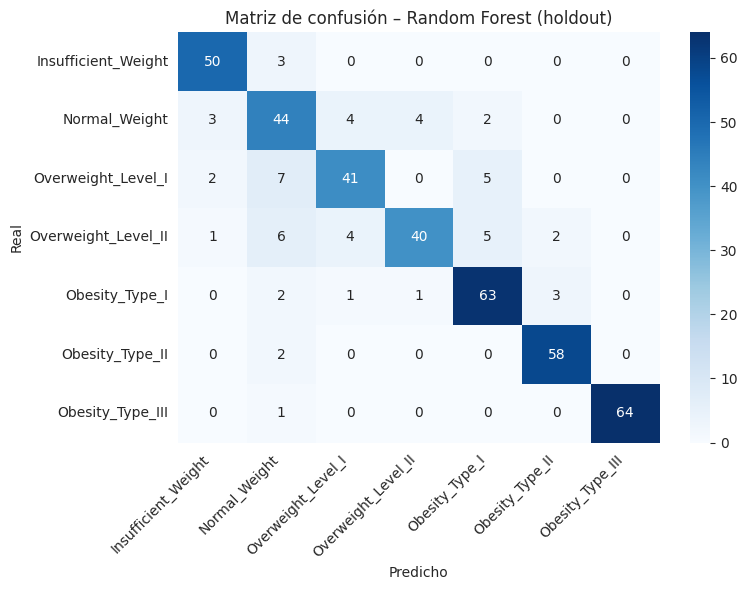

In [18]:
# Matriz de confusión con las clases ordenadas de menor a mayor peso
orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
idx = [list(le.classes_).index(c) for c in orden]
cm = confusion_matrix(y_val_enc, y_pred, labels=idx)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=orden, yticklabels=orden)
plt.xlabel('Predicho'); plt.ylabel('Real'); plt.title(f'Matriz de confusión – {ganador} (holdout)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

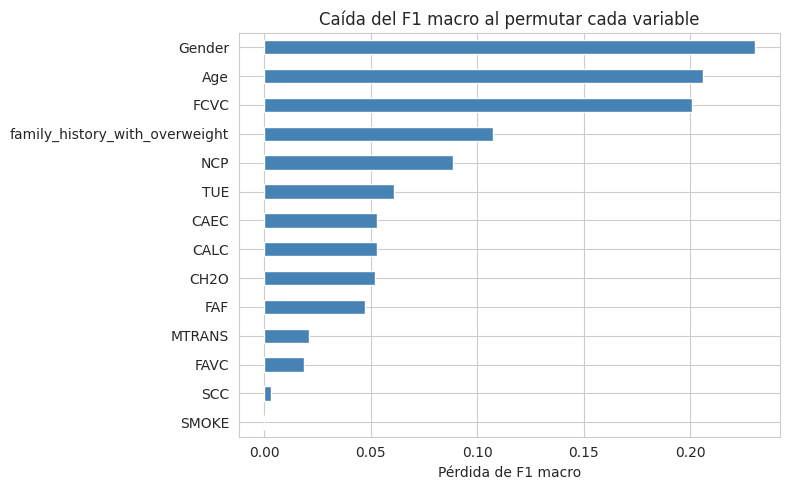

In [19]:
# Importancia de variables por permutación (sobre las variables originales)
pi = permutation_importance(modelo_final, X_val, y_val_enc, scoring='f1_macro',
                            n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values()
imp.plot(kind='barh', color='steelblue', figsize=(8, 5))
plt.title('Caída del F1 macro al permutar cada variable'); plt.xlabel('Pérdida de F1 macro')
plt.tight_layout(); plt.show()

# 6. Motor de recomendaciones
Reglas simples basadas en la clase predicha y en los hábitos modificables
de la persona (no se diagnostica: se sugiere consultar a un profesional).

In [20]:
def recomendar(persona: dict):
    """persona: dict con las mismas columnas que X (sin Height/Weight)."""
    df_p = pd.DataFrame([persona])
    clase = le.inverse_transform(modelo_final.predict(df_p))[0]
    sug = []
    if persona['FAF'] < 1:
        sug.append('Sumar actividad física: al menos 150 min semanales de actividad moderada.')
    if persona['TUE'] >= 2:
        sug.append('Reducir el tiempo frente a pantallas y cortar con pausas activas.')
    if persona['FAVC'] == 'yes':
        sug.append('Bajar la frecuencia de alimentos hipercalóricos.')
    if persona['FCVC'] < 2:
        sug.append('Incorporar verduras en la mayoría de las comidas.')
    if persona['CH2O'] < 2:
        sug.append('Aumentar el consumo de agua (1 a 2 litros diarios).')
    if persona['CAEC'] in ('Frequently', 'Always'):
        sug.append('Evitar picotear entre comidas; planificar colaciones saludables.')
    if persona['CALC'] in ('Frequently', 'Always'):
        sug.append('Reducir el consumo de alcohol.')
    if persona['MTRANS'] in ('Automobile', 'Public_Transportation'):
        sug.append('Cuando se pueda, reemplazar tramos en auto/colectivo por caminata o bici.')
    if persona['SCC'] == 'no' and 'Obesity' in clase:
        sug.append('Llevar un registro de lo que se come (o de calorías) durante unas semanas.')
    if clase == 'Insufficient_Weight':
        sug = ['Consultar a un profesional de nutrición para alcanzar un peso saludable.']
    elif clase == 'Normal_Weight' and not sug:
        sug = ['Tus hábitos son compatibles con un peso normal: ¡mantenelos!']
    if 'Obesity' in clase:
        sug.append('Recomendamos una consulta médica/nutricional para un plan personalizado.')
    return clase, sug

ejemplo = X_val.iloc[0].to_dict()
clase, sugerencias = recomendar(ejemplo)
print('Nivel predicho:', clase)
for s in sugerencias:
    print(' -', s)

Nivel predicho: Overweight_Level_II
 - Cuando se pueda, reemplazar tramos en auto/colectivo por caminata o bici.
